<a href="https://colab.research.google.com/github/soumensen411/Deep-Learning-Model/blob/main/CNN/Few-Shot%20%26%20Zero%20Shot%20Learning/few_zero_shot_v2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [115]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [116]:
import torch
import torch.nn as nn
import torchvision.models as models
import torchvision.transforms as transforms
from PIL import Image

# Load pretrained ResNet18
weights = models.ResNet18_Weights.DEFAULT

model = models.resnet18(weights=weights)

# Remove final classification layer
model.fc = nn.Identity()

model = model.to(device)
model.eval()

print("ResNet18 loaded successfully!")

ResNet18 loaded successfully!


In [117]:
device = "cuda" if torch.cuda.is_available() else "cpu"

print("Using device:", device)

Using device: cpu


In [118]:

import torchvision
import torchvision.transforms as transforms

# ImageNet preprocessing for ResNet18
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# Download and load training images
train_data = torchvision.datasets.OxfordIIITPet(
    root="./data",
    split="trainval",
    target_types="binary-category",
    transform=transform,
    download=True
)

# Load test images for Few-Shot
test_data = torchvision.datasets.OxfordIIITPet(
    root="./data",
    split="test",
    target_types="binary-category",
    transform=transform,
    download=True
)

# Load original images for CLIP and visualization
test_data_raw = torchvision.datasets.OxfordIIITPet(
    root="./data",
    split="test",
    target_types="binary-category",
    transform=None,
    download=False
)

# Binary class labels
class_ids = {
    "cat": 0,
    "dog": 1
}

print("Dataset loaded successfully!")
print("Training images:", len(train_data))
print("Testing images:", len(test_data))
print("Classes:", train_data.bin_classes)


Dataset loaded successfully!
Training images: 3680
Testing images: 3669
Classes: ['Cat', 'Dog']


In [119]:

from collections import defaultdict

support_images = defaultdict(list)

# Collect 2 images per class
for image, label in train_data:

    for class_name, class_id in class_ids.items():

        if label == class_id and len(support_images[class_name]) < 2:
            support_images[class_name].append(image)

    if all(
        len(support_images[name]) == 2
        for name in class_ids
    ):
        break

# Verify
for name, images in support_images.items():
    print(name, ":", len(images))

assert all(
    len(support_images[name]) == 2
    for name in class_ids
), "Missing support images!"

print("Total support images:", sum(
    len(images) for images in support_images.values()
))


cat : 2
dog : 2
Total support images: 4


In [120]:
# Select one query image from test dataset
query_index = 0

query_image, actual_label = test_data[query_index]

actual_class = {
    0: "cat",
    1: "dog"
}[actual_label]

print("Actual class:", actual_class)

Actual class: cat


In [121]:

def extract_features(images):
    batch = torch.stack(images).to(device)

    with torch.no_grad():
        features = model(batch)

    return features

# Extract support features
prototypes = {}

for class_name, images in support_images.items():

    features = extract_features(images)

    # Average features = class prototype
    prototypes[class_name] = features.mean(dim=0)

print("Class prototypes created!")


Class prototypes created!


Few-Shot Prediction: cat
Actual: cat

Distances:
cat : 19.0548
dog : 22.0795


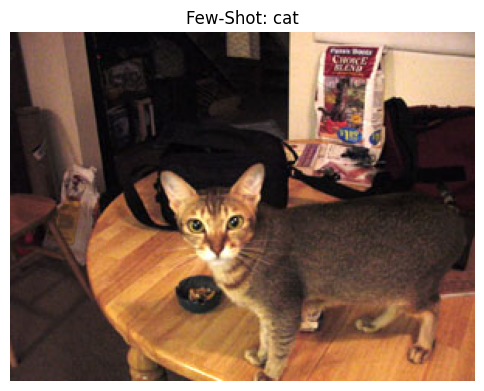

In [122]:
# Extract query image features
query_feature = extract_features([query_image])[0]

# Calculate distances
distances = {}

for class_name, prototype in prototypes.items():

    distance = torch.norm(
        query_feature - prototype
    )

    distances[class_name] = distance.item()

# Predict nearest class
few_shot_prediction = min(
    distances,
    key=distances.get
)

print("Few-Shot Prediction:", few_shot_prediction)
print("Actual:", actual_class)

print("\nDistances:")

for name, distance in distances.items():
    print(name, ":", round(distance, 4))

# Display original high-resolution image
raw_image, _ = test_data_raw[query_index]

plt.figure(figsize=(6, 6))
plt.imshow(raw_image)
plt.title(f"Few-Shot: {few_shot_prediction}")
plt.axis("off")
plt.show()

# Zero-Shot Learning Implementation

In [123]:

from transformers import CLIPProcessor, CLIPModel

clip_model = CLIPModel.from_pretrained(
    "openai/clip-vit-base-patch32"
)

processor = CLIPProcessor.from_pretrained(
    "openai/clip-vit-base-patch32"
)

clip_model = clip_model.to(device)
clip_model.eval()

print("CLIP loaded successfully!")


Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

CLIP loaded successfully!


In [124]:
text_prompts = [
    "A photo of a cat",
    "A photo of a dog"
]

Zero-Shot Prediction: cat
Actual: cat

Similarity Scores:
A photo of a cat : 99.44 %
A photo of a dog : 0.56 %


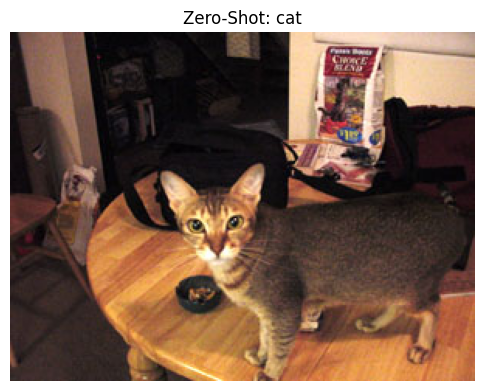

In [127]:
# Load our target query image from the raw dataset
query_image_pil, actual_label = test_data_raw[query_index]

# Tokenize the text prompts and preprocess the image for CLIP
inputs = processor(
    text=text_prompts,
    images=query_image_pil,
    return_tensors="pt",
    padding=True
)

inputs = {
    key: value.to(device)
    for key, value in inputs.items()
}

# Run the model forward pass to compute similarities
with torch.inference_mode():
    outputs = clip_model(**inputs)
    probabilities = outputs.logits_per_image.softmax(dim=1)

best_index = probabilities.argmax(dim=1).item()
zero_shot_prediction = ["cat", "dog"][best_index]

print("Zero-Shot Prediction:", zero_shot_prediction)
print("Actual:", actual_class)

print("\nSimilarity Scores:")
for text, score in zip(
    text_prompts,
    probabilities[0].tolist()
):
    print(text, ":", round(score * 100, 2), "%")

# Plot the query image and show our final prediction
plt.figure(figsize=(6, 6))
plt.imshow(query_image_pil)
plt.title(f"Zero-Shot: {zero_shot_prediction}")
plt.axis("off")
plt.show()

In [126]:
print("========== FINAL RESULTS ==========")

print("Actual:", actual_class)

print("Few-Shot Prediction:", few_shot_prediction)
print("Zero-Shot Prediction:", zero_shot_prediction)

print("\nFew-Shot Correct:",
      few_shot_prediction == actual_class)

print("Zero-Shot Correct:",
      zero_shot_prediction == actual_class)

========== FINAL RESULTS ==========
Actual: cat
Few-Shot Prediction: cat
Zero-Shot Prediction: cat

Few-Shot Correct: True
Zero-Shot Correct: True
